# 03 — Model Training and Evaluation

## 1. Introduction and Objectives

**Objective:** Train, evaluate, optimize, and compare six supervised machine-learning classifiers for predicting historical firewall actions from network-flow records.

**Task:** Four-class supervised classification of `Action`: `allow`, `deny`, `drop`, `reset-both`.

**Dataset from Notebook 02:** 57,170 deduplicated flows; 45,736 training and 11,434 held-out testing rows. These numbers are documented expectations and are checked against the local files rather than treated as model results.

**Six algorithms:** Dummy (Zero-R), KNN, Decision Tree, Random Forest, Gaussian Naive Bayes, and linear Support Vector Machine (SVM).

**Leakage controls:**
- No test-set access before the final evaluation step.
- Every transformation is **fitted inside** cross-validation folds through `sklearn.pipeline.Pipeline`.
- Group-aware CV prevents identical full-feature rows from appearing in both training and validation folds.
- Feature-set ablations test `full` (11), `without_nat` (9), and `ports_only` (2) from `src/preprocessing.py`.

**Important limitation:** `Bytes`, `Packets`, and NAT fields may contain information only known after a firewall action. Accordingly, a high score using all fields **does not** by itself establish that the model can predict a decision before it occurs. The `ports_only` experiment provides a stricter decision-time comparison.

## 2. Reproducible Environment & Imports

Run all cells from top to bottom. Use the repository `.venv` Python kernel with the packages from `requirements.txt`. The pipeline uses the project's **existing** `src/preprocessing.py`, not a second inconsistent implementation.

In [1]:
from pathlib import Path
import sys
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root whether VS Code starts here or inside notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "preprocessing.py").exists():
    raise FileNotFoundError(
        "Cannot locate src/preprocessing.py. Open the repository folder in VS Code "
        "and run the notebook from its root or notebooks/ directory."
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing import make_preprocessor, get_feature_columns
RANDOM_STATE = 42
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])

Repository: /home/aehmk63/Desktop/Firewall-Traffic-Analyzer
Python: 3.14.4


## 3. Load Preprocessed Training Data

Load **only** `data/processed/train.csv` created in Notebook 02. Do **not** load `test.csv` during model exploration, selection, or hyperparameter tuning.

In [2]:
train_path = ROOT / "data" / "processed" / "train.csv"
if not train_path.exists():
    raise FileNotFoundError(
        f"Missing {train_path}. Run Notebook 02 to export train.csv first."
    )
train_df = pd.read_csv(train_path)
if "Action" not in train_df.columns:
    raise KeyError("train.csv must contain the target column 'Action'.")

X_train = train_df.drop(columns=["Action"])
y_train = train_df["Action"].astype(str).str.strip().str.lower()
CLASS_LABELS = ["allow", "deny", "drop", "reset-both"]
if not set(y_train.unique()).issubset(set(CLASS_LABELS)):
    raise ValueError(f"Unexpected target labels: {set(y_train.unique())}")
if y_train.isna().any() or X_train.isna().any().any():
    raise ValueError("Missing values detected. Inspect the split and preprocessing before training.")
needed = get_feature_columns("full")
missing = [c for c in needed if c not in X_train.columns]
if missing:
    raise KeyError(f"Required features missing from train.csv: {missing}")

print("Training features shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
class_counts = y_train.value_counts().reindex(CLASS_LABELS, fill_value=0)
class_shares = (100 * class_counts / len(y_train)).round(4)
display(pd.DataFrame({"Count": class_counts, "Percentage (%)": class_shares}))
if len(X_train) != 45736:
    print("Note: train.csv row count differs from the original Notebook 02 export; inspect the split.")

Training features shape: (45736, 11)
Training labels shape: (45736,)


,Count,Percentage (%)
Action,,
allow,29951,65.4867
deny,6434,14.0677
drop,9308,20.3516
reset-both,43,0.0940


## 4. Group-aware Cross-validation & Evaluation Metrics

Build group IDs from **all 11 original features**. The same full-feature signature is kept within a single CV fold, even when evaluating reduced feature sets. This prevents exact duplicates from leaking into validation. The **primary selection metric is macro F1**, because `reset-both` is very rare. Secondary metrics: weighted F1, accuracy, and balanced accuracy. Fixed labels in macro F1 ensure absent validation classes are not silently omitted.

Fold-level scores are validation results, **not** held-out test results.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import f1_score, balanced_accuracy_score

# Stable group identifiers for identical original feature combinations.
cv_groups = pd.util.hash_pandas_object(
    X_train[get_feature_columns("full")], index=False
).to_numpy()
group_counts = pd.Series(cv_groups).groupby(y_train.to_numpy()).nunique()
print("Distinct signatures by class:")
print(group_counts)
min_group_count = int(group_counts.min())
if min_group_count < 2:
    raise ValueError("At least two independent full-feature groups per class are needed for cross-validation.")
CV_FOLDS = min(5, min_group_count)
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
def macro_f1_scorer(estimator, X, y):
    return f1_score(y, estimator.predict(X), labels=CLASS_LABELS, average="macro", zero_division=0)

def weighted_f1_scorer(estimator, X, y):
    return f1_score(y, estimator.predict(X), labels=CLASS_LABELS, average="weighted", zero_division=0)

SCORING = {
    "f1_macro": macro_f1_scorer,
    "f1_weighted": weighted_f1_scorer,
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
}
# Leakage sanity-check on the exact same split strategy.
for fold, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train, cv_groups), 1):
    assert set(cv_groups[tr_idx]).isdisjoint(set(cv_groups[val_idx]))
    print(f"Fold {fold}: train={len(tr_idx):,}, validation={len(val_idx):,}")

Distinct signatures by class:
allow         29951
deny           6434
drop           9308
reset-both       43
dtype: int64
Fold 1: train=36,588, validation=9,148
Fold 2: train=36,589, validation=9,147
Fold 3: train=36,589, validation=9,147
Fold 4: train=36,589, validation=9,147
Fold 5: train=36,589, validation=9,147


## 5. Define the Six Classifiers

All models receive **in-fold preprocessing** from `src.preprocessing.make_preprocessor`. Models are compared on the same full-feature set.

- Dummy: majority-class baseline.
- KNN: Euclidean nearest-neighbor learning over transformed features.
- Tree and Random Forest: nonlinear decision boundaries.
- GaussianNB: the preprocessor is asked for a **dense** output (`sparse_threshold=0.0`) because `GaussianNB` cannot directly accept sparse matrices. This uses more RAM.
- SVM: `LinearSVC` is a *linear* support-vector classifier chosen instead of an expensive kernel SVM for this dataset. Report it as **Linear SVM**, not RBF SVM.

`class_weight="balanced"` is applied where supported. It does not guarantee reliable estimates for a class with only ~43 training rows.

In [4]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

def build_model(model_name, feature_set="full"):
    preprocessor = make_preprocessor(feature_set)
    if model_name == "Gaussian Naive Bayes":
        # Force a dense array for GaussianNB without any custom, non-picklable code.
        preprocessor.set_params(sparse_threshold=0.0)
    estimators = {
        "Dummy (Zero-R)": DummyClassifier(strategy="most_frequent"),
        "KNN": KNeighborsClassifier(n_neighbors=11, weights="distance", n_jobs=-1),
        "Decision Tree": DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                                 class_weight="balanced_subsample", n_jobs=-1,
                                                 random_state=RANDOM_STATE),
        "Gaussian Naive Bayes": GaussianNB(),
        "Linear SVM": LinearSVC(C=1.0, class_weight="balanced", max_iter=8000,
                                random_state=RANDOM_STATE),
    }
    if model_name not in estimators:
        raise KeyError(f"Unknown model: {model_name}")
    return Pipeline([("preprocessing", preprocessor), ("classifier", estimators[model_name])])

MODEL_NAMES = ["Dummy (Zero-R)", "KNN", "Decision Tree", "Random Forest", "Gaussian Naive Bayes", "Linear SVM"]
print("Models:", MODEL_NAMES)

Models: ['Dummy (Zero-R)', 'KNN', 'Decision Tree', 'Random Forest', 'Gaussian Naive Bayes', 'Linear SVM']


## 6. Cross-validate and Compare All Six Models

These are **out-of-fold CV scores**. No test file is loaded here. Each model is fitted separately within each fold. You can change `CV_FOLDS` in Step 04 if you need a diagnostic run with fewer folds; keep **5** for the documented main experiment if group counts permit it.

**Performance note:** Five-fold validation across six models, particularly KNN and GaussianNB, can be demanding on a laptop. Run the cell intentionally; it is not precomputed.

In [5]:
bench_rows = []
for model_name in MODEL_NAMES:
    print(f"Evaluating: {model_name}")
    pipeline = build_model(model_name, "full")
    start = time.perf_counter()
    result = cross_validate(
        pipeline, X_train[get_feature_columns("full")], y_train,
        cv=cv, groups=cv_groups, scoring=SCORING,
        n_jobs=1, return_train_score=False, error_score="raise",
    )
    record = {"model": model_name, "seconds": round(time.perf_counter() - start, 2)}
    for metric in SCORING:
        record[f"{metric}_mean"] = float(np.mean(result[f"test_{metric}"]))
        record[f"{metric}_std"] = float(np.std(result[f"test_{metric}"]))
    bench_rows.append(record)
    print(f"  macro F1 = {record['f1_macro_mean']:.4f} (+/- {record['f1_macro_std']:.4f})")

comparison_df = pd.DataFrame(bench_rows).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)
display(comparison_df.style.format({c: "{:.4f}" for c in comparison_df.select_dtypes("number").columns if c != "seconds"}))
print("Top CV model:", comparison_df.iloc[0]["model"])

Evaluating: Dummy (Zero-R)
  macro F1 = 0.1979 (+/- 0.0000)
Evaluating: KNN
  macro F1 = 0.8477 (+/- 0.0378)
Evaluating: Decision Tree
  macro F1 = 0.7455 (+/- 0.0034)
Evaluating: Random Forest
  macro F1 = 0.7464 (+/- 0.0028)
Evaluating: Gaussian Naive Bayes
  macro F1 = 0.7074 (+/- 0.0055)
Evaluating: Linear SVM
  macro F1 = 0.8113 (+/- 0.0168)


,model,seconds,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std
0,KNN,213.650000,0.8477,0.0378,0.9981,0.0003,0.8138,0.0322,0.9984,0.0002
1,Linear SVM,18.130000,0.8113,0.0168,0.9976,0.0004,0.8125,0.0307,0.9975,0.0008
2,Random Forest,28.970000,0.7464,0.0028,0.9867,0.0012,0.9314,0.0316,0.9780,0.0020
3,Decision Tree,15.240000,0.7455,0.0034,0.9862,0.0010,0.9362,0.0225,0.9771,0.0016
4,Gaussian Naive Bayes,14.920000,0.7074,0.0055,0.9677,0.0025,0.9147,0.0065,0.9483,0.0034
5,Dummy (Zero-R),9.470000,0.1979,0.0000,0.5183,0.0001,0.2500,0.0000,0.6549,0.0001


Top CV model: KNN


## 7. Visualize CV Results and Optional Hyperparameter Search

We first rank **model families** using macro F1. Hyperparameter tuning is optional and uses the training data only. To avoid inadvertent long-running training, `RUN_TUNING=False` initially. Set it to `True` to tune the CV winner with a small grid.

The best score reported by `GridSearchCV` is a **selection/tuning** score, not an unbiased held-out test score. The held-out test set is used later, once.

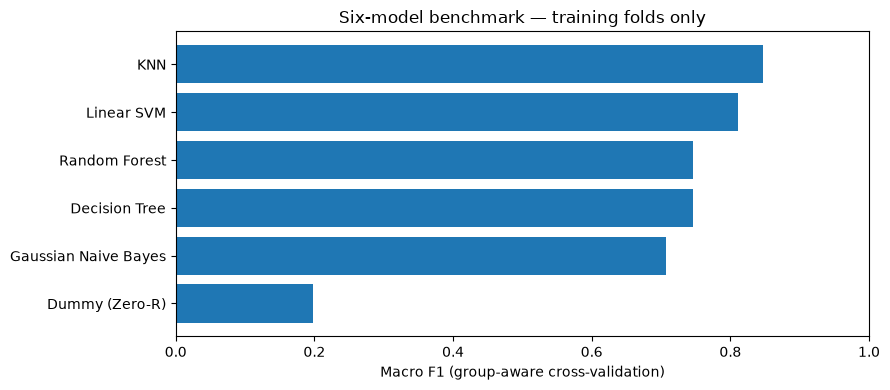

Optional tuning skipped. Set RUN_TUNING = True and rerun this cell to tune the winner.


In [6]:
from sklearn.model_selection import GridSearchCV

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison_df["model"][::-1], comparison_df["f1_macro_mean"][::-1])
ax.set_xlabel("Macro F1 (group-aware cross-validation)")
ax.set_xlim(0, 1)
ax.set_title("Six-model benchmark — training folds only")
plt.tight_layout()
plt.show()

# All grids use the classifier step of the project preprocessing pipeline.
PARAM_GRIDS = {
    "Dummy (Zero-R)": {"classifier__strategy": ["most_frequent", "prior"]},
    "KNN": {"classifier__n_neighbors": [5, 11, 21], "classifier__weights": ["uniform", "distance"]},
    "Decision Tree": {"classifier__max_depth": [10, 20, None], "classifier__min_samples_leaf": [2, 5]},
    "Random Forest": {"classifier__n_estimators": [100, 150], "classifier__min_samples_leaf": [2, 5]},
    "Gaussian Naive Bayes": {"classifier__var_smoothing": [1e-9, 1e-8, 1e-7]},
    "Linear SVM": {"classifier__C": [0.1, 1.0, 10.0]},
}
RUN_TUNING = False
winner_model_name = str(comparison_df.iloc[0]["model"])
tuned_parameters = {}
if RUN_TUNING:
    search = GridSearchCV(
        build_model(winner_model_name, "full"),
        param_grid=PARAM_GRIDS[winner_model_name],
        scoring=SCORING["f1_macro"], cv=cv, n_jobs=1, refit=True, verbose=1,
        error_score="raise",
    )
    search.fit(X_train[get_feature_columns("full")], y_train, groups=cv_groups)
    tuned_parameters = search.best_params_
    print("Best search parameters:", tuned_parameters)
    print("Best tuning macro F1:", search.best_score_)
else:
    print("Optional tuning skipped. Set RUN_TUNING = True and rerun this cell to tune the winner.")

## 8. Feature-Set Ablation Before Opening the Test Set

Compare the **selected model family** using `full`, `without_nat`, and `ports_only`. The last scenario uses only source and destination ports and avoids features that may not be available at firewall decision time. The model/feature combination is chosen by training-only cross-validation.

**Caution:** The source/destination ports still may not be sufficient for realistic real-time policy enforcement. The target is an observed action in logs, not necessarily a causal decision rule.

In [7]:
FEATURE_SCENARIOS = ["full", "without_nat", "ports_only"]
ablations = []
for scenario in FEATURE_SCENARIOS:
    selected_cols = get_feature_columns(scenario)
    candidate = build_model(winner_model_name, scenario)
    if tuned_parameters:
        candidate.set_params(**tuned_parameters)
    cv_result = cross_validate(
        candidate, X_train[selected_cols], y_train,
        cv=cv, groups=cv_groups, scoring=SCORING,
        n_jobs=1, error_score="raise",
    )
    ablations.append({
        "feature_set": scenario,
        "n_features": len(selected_cols),
        "f1_macro_mean": float(np.mean(cv_result["test_f1_macro"])),
        "f1_macro_std": float(np.std(cv_result["test_f1_macro"])),
        "balanced_accuracy_mean": float(np.mean(cv_result["test_balanced_accuracy"])),
    })
ablation_df = pd.DataFrame(ablations).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)
display(ablation_df)
best_scenario = str(ablation_df.iloc[0]["feature_set"])
best_columns = get_feature_columns(best_scenario)
print("Selected by training CV:", winner_model_name, "+", best_scenario)

,feature_set,n_features,f1_macro_mean,f1_macro_std,balanced_accuracy_mean
0,full,11,0.847747,0.037782,0.813820
1,without_nat,9,0.847652,0.037849,0.813726
2,ports_only,2,0.683378,0.008144,0.696818


Selected by training CV: KNN + full


## 9. Final Fit and One-time Held-out Test Evaluation

**Only now** do we load `data/processed/test.csv`. Fit the chosen pipeline once on the complete training split, evaluate it once on the untouched test split, and display a confusion matrix and per-class precision/recall/F1.

Because `reset-both` has very few examples, interpret its per-class metrics cautiously. The reported results describe historical classification and should not be presented as deployed firewall security performance.

Identical full-feature signatures across train/test: 0
Held-out test metrics: {
  "accuracy": 0.9984257477698093,
  "balanced_accuracy": 0.7716055775174245,
  "f1_macro": 0.7898770007371495,
  "f1_weighted": 0.9980627721227328
}


,precision,recall,f1-score,support
allow,1.000000,0.999866,0.999933,7488.000000
deny,0.993176,0.995647,0.994410,1608.000000
drop,0.997001,1.000000,0.998498,2327.000000
reset-both,1.000000,0.090909,0.166667,11.000000
accuracy,0.998426,0.998426,0.998426,0.998426
macro avg,0.997544,0.771606,0.789877,11434.000000
weighted avg,0.998430,0.998426,0.998063,11434.000000


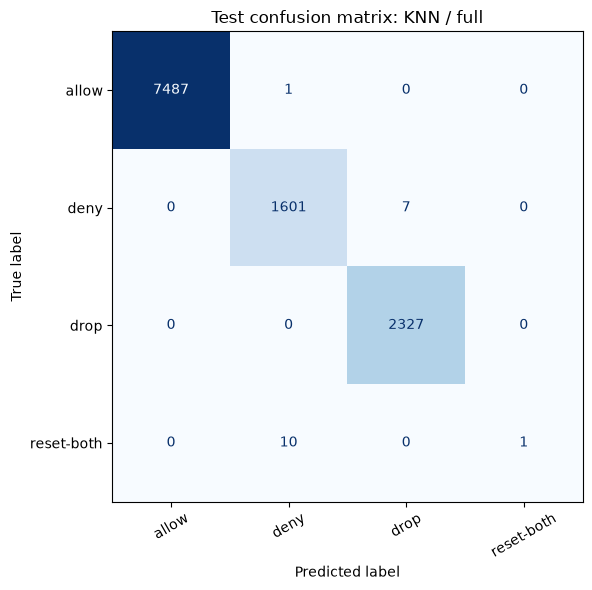

In [8]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

test_path = ROOT / "data" / "processed" / "test.csv"
if not test_path.exists():
    raise FileNotFoundError(f"Missing {test_path}. Run Notebook 02 first.")
test_df = pd.read_csv(test_path)
if "Action" not in test_df.columns:
    raise KeyError("test.csv must contain the target column 'Action'.")
X_test = test_df.drop(columns=["Action"])
y_test = test_df["Action"].astype(str).str.strip().str.lower()
if not set(y_test.unique()).issubset(set(CLASS_LABELS)):
    raise ValueError(f"Unexpected labels in test.csv: {set(y_test.unique())}")
if any(c not in X_test.columns for c in best_columns):
    raise KeyError("test.csv lacks one or more model input columns.")

# Guard against accidental exact-feature overlap between the exported splits.
train_signatures = set(pd.util.hash_pandas_object(X_train[get_feature_columns("full")], index=False))
test_signatures = set(pd.util.hash_pandas_object(X_test[get_feature_columns("full")], index=False))
overlap = len(train_signatures & test_signatures)
print("Identical full-feature signatures across train/test:", overlap)
if overlap:
    raise ValueError("Train/test share identical original feature patterns. Review Notebook 02 group splitting.")

final_pipeline = build_model(winner_model_name, best_scenario)
if tuned_parameters:
    final_pipeline.set_params(**tuned_parameters)
final_pipeline.fit(X_train[best_columns], y_train)
y_pred = final_pipeline.predict(X_test[best_columns])

test_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "f1_macro": float(f1_score(y_test, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0)),
    "f1_weighted": float(f1_score(y_test, y_pred, labels=CLASS_LABELS, average="weighted", zero_division=0)),
}
print("Held-out test metrics:", json.dumps(test_metrics, indent=2))
report = classification_report(y_test, y_pred, labels=CLASS_LABELS, zero_division=0, output_dict=True)
display(pd.DataFrame(report).T)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASS_LABELS, ax=ax,
                                        cmap="Blues", xticks_rotation=30, colorbar=False)
ax.set_title(f"Test confusion matrix: {winner_model_name} / {best_scenario}")
plt.tight_layout()
plt.show()

## 10. Export a Deployable Pipeline and Reproducible Reports

Export the **fitted full pipeline** (including in-fold-trained preprocessing), its expected input columns and label order, and the measured test metrics for the Streamlit teammate. No artifact is created until the preceding training and evaluation cells have completed.

Artifacts:
- `models/firewall_pipeline.joblib` — fitted pipeline, ready for `.predict()`.
- `models/metadata.json` — feature order, classes, model/scenario selection.
- `models/metrics.json` — held-out test results.
- `reports/model_comparison.csv`, `reports/feature_ablation.csv`, `reports/classification_report.csv`.

Check the app's expected artifact paths before integrating; these are the notebook's proposed interface. Do **not** automatically commit large `.joblib` files to Git.

In [9]:
from datetime import datetime, timezone

models_dir = ROOT / "models"
reports_dir = ROOT / "reports"
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(final_pipeline, models_dir / "firewall_pipeline.joblib")
metadata = {
    "project": "Intelligent Firewall Traffic Analyzer",
    "training_source": "data/processed/train.csv",
    "test_source": "data/processed/test.csv",
    "model_name": winner_model_name,
    "feature_set": best_scenario,
    "feature_columns": best_columns,
    "class_labels": CLASS_LABELS,
    "random_state": RANDOM_STATE,
    "cv_folds": CV_FOLDS,
    "selection_metric": "macro_f1",
    "best_params": tuned_parameters,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "warning": "Historical action prediction; full-feature measurements may be post-decision variables.",
}
with (models_dir / "metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
with (models_dir / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump({"test": test_metrics, "cv_model_comparison": comparison_df.to_dict(orient="records"),
               "cv_feature_ablation": ablation_df.to_dict(orient="records")}, f, indent=2)
comparison_df.to_csv(reports_dir / "model_comparison.csv", index=False)
ablation_df.to_csv(reports_dir / "feature_ablation.csv", index=False)
pd.DataFrame(report).T.to_csv(reports_dir / "classification_report.csv")
print("Exported fitted model and metadata:", models_dir)
print("Exported reports:", reports_dir)

Exported fitted model and metadata: /home/aehmk63/Desktop/Firewall-Traffic-Analyzer/models
Exported reports: /home/aehmk63/Desktop/Firewall-Traffic-Analyzer/reports


## 11. Integration Smoke Test & Conclusions

Reload the pipeline from disk and compare its predictions with the in-memory pipeline. This catches some packaging errors before the Streamlit teammate integrates the artifact.

**Team handoff:** The Streamlit interface must load `models/firewall_pipeline.joblib`, read `models/metadata.json`, construct one DataFrame with precisely `feature_columns` in that order, then call `.predict()`. Do not re-encode or separately rescale the inputs in the UI because the saved pipeline already contains preprocessing.

**Report:** Cite CV and held-out test results separately; discuss minority-class limitations and the choice between full features and a causally plausible ports-only setting.

In [10]:
reloaded = joblib.load(models_dir / "firewall_pipeline.joblib")
small_batch = X_test[best_columns].head(min(5, len(X_test)))
assert np.array_equal(final_pipeline.predict(small_batch), reloaded.predict(small_batch))
print("Smoke test passed: saved pipeline reproduces predictions.")
print("Chosen model:", winner_model_name)
print("Chosen feature scenario:", best_scenario)
print("Held-out macro F1:", round(test_metrics["f1_macro"], 4))
print("Milestone 03 complete only if all cells ran and the artifacts were reviewed.")

Smoke test passed: saved pipeline reproduces predictions.
Chosen model: KNN
Chosen feature scenario: full
Held-out macro F1: 0.7899
Milestone 03 complete only if all cells ran and the artifacts were reviewed.
